# The mboost and gamboostLSS tutorials in mboostrs

This chapter follows the two package tutorials — Hothorn et al.'s *Model-based
Boosting 2.0* vignette for `mboost` and Hofner et al.'s tutorial for
`gamboostLSS` — step by step, in mboostrs. The data, the model specifications
and the order of the analysis are theirs. The R call appears above each step,
so a reader who knows the tutorials can find their place.

Differences are explained at the step where they affect the analysis and
summarized in the final table. Values shown here are computed by this notebook;
values attributed to R come from the tutorials run under `mboost` 2.9-11 and
`gamboostLSS` 2.1-0.

In [1]:
import numpy as np
import polars as pl

import mboostrs as mb

bodyfat = mb.datasets.bodyfat()
print(f"{bodyfat.height} observations, {bodyfat.width} columns")
print(", ".join(bodyfat.columns))

71 observations, 10 columns
age, DEXfat, waistcirc, hipcirc, elbowbreadth, kneebreadth, anthro3a, anthro3b, anthro3c, anthro4


## Linear model: `glmboost` and `lm`

The tutorial opens by fitting three predictors with `lm`, then the same three
with `glmboost`, to show that boosting approaches the least-squares solution.

```r
lm1  <- lm(DEXfat ~ hipcirc + kneebreadth + anthro3a, data = bodyfat)
glm1 <- glmboost(DEXfat ~ hipcirc + kneebreadth + anthro3a, data = bodyfat)
coef(glm1, off2int = TRUE)   ## off2int adds the offset to the intercept
```

`off2int` has no counterpart here: mboostrs reports the intercept and the
offset as separate entries, and adding them gives R's number.

In [2]:
formula = "DEXfat ~ hipcirc + kneebreadth + anthro3a"
glm1 = mb.glmboost(formula, data=bodyfat, family=mb.Gaussian(),
                   control=mb.boost_control(100, 0.1))

coefficients = glm1.coef()
intercept = float(coefficients["(Intercept)"]) + float(glm1._offset)
rows = [{"term": "(Intercept)", "mboostrs": round(intercept, 4),
         "R glmboost": -75.2073, "R lm": -75.2348}]
for name, r_glm, r_lm in (("hipcirc", 0.5115, 0.5115),
                          ("kneebreadth", 1.9005, 1.9020),
                          ("anthro3a", 8.9071, 8.9096)):
    rows.append({"term": name, "mboostrs": round(float(coefficients[name]), 4),
                 "R glmboost": r_glm, "R lm": r_lm})
display(pl.DataFrame(rows))

term,mboostrs,R glmboost,R lm
"""(Intercept)""",-75.2073,-75.2073,-75.2348
"""hipcirc""",0.5115,0.5115,0.5115
"""kneebreadth""",1.9005,1.9005,1.902
"""anthro3a""",8.9071,8.9071,8.9096


At 100 iterations the boosted coefficients are close to, but smaller than,
the `lm` coefficients because each update is shrunk toward zero. Increasing
the stopping iteration reduces that shrinkage.

## Coefficients of unselected predictors

```r
glm2 <- glmboost(DEXfat ~ ., data = bodyfat)
coef(glm2, which = "")   ## which = "" selects all base-learners
```

`which = ""` asks R to report every base-learner including those never
selected. mboostrs returns only the terms with a non-zero coefficient, so an absent predictor was never selected.

In [3]:
predictors = [c for c in bodyfat.columns if c != "DEXfat"]
glm2 = mb.glmboost("DEXfat ~ " + " + ".join(predictors), data=bodyfat,
                   family=mb.Gaussian(), control=mb.boost_control(100, 0.1))

fitted_coefficients = glm2.coef()
r_values = {"(Intercept)": -98.8166, "age": 0.0136, "waistcirc": 0.1897,
            "hipcirc": 0.3516, "elbowbreadth": -0.3841, "kneebreadth": 1.7366,
            "anthro3a": 3.3269, "anthro3b": 3.6565, "anthro3c": 0.5954,
            "anthro4": 0.0000}
rows = []
for name, r_value in r_values.items():
    value = fitted_coefficients.get(name)
    rows.append({
        "term": name,
        "mboostrs": round(float(value), 4) if value is not None else None,
        "R": r_value,
    })
display(pl.DataFrame(rows))
print("anthro4 is absent from the mboostrs result and 0.0000 in R's: "
      "it was never selected")

term,mboostrs,R
"""(Intercept)""",-98.8166,-98.8166
"""age""",0.0136,0.0136
"""waistcirc""",0.1897,0.1897
"""hipcirc""",0.3516,0.3516
"""elbowbreadth""",-0.3841,-0.3841
"""kneebreadth""",1.7366,1.7366
"""anthro3a""",3.3269,3.3269
"""anthro3b""",3.6565,3.6565
"""anthro3c""",0.5954,0.5954
"""anthro4""",null,0.0


anthro4 is absent from the mboostrs result and 0.0000 in R's: it was never selected


```r
plot(glm2, off2int = TRUE)   ## coefficient paths
```

The tutorial next plots the coefficient paths. In R, `plot` dispatches on
the model class; mboostrs provides named plot functions for coefficient paths,
risk, and partial effects.

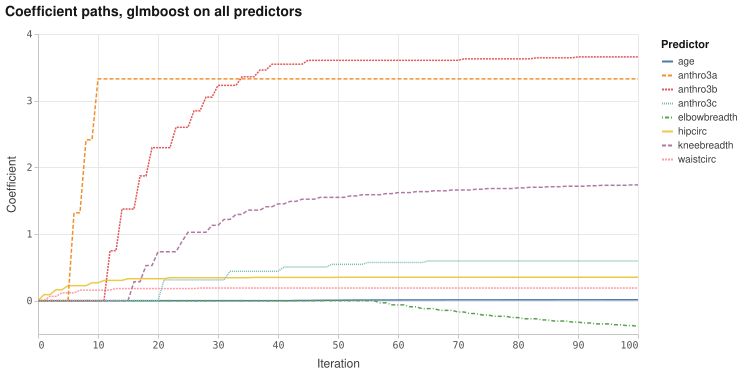

In [4]:
mb.plot.plot_coef_path(glm2).properties(
    title="Coefficient paths, glmboost on all predictors")

## Smooth effects

```r
gam1 <- gamboost(DEXfat ~ bbs(hipcirc) + bbs(kneebreadth) + bbs(anthro3a),
                 data = bodyfat)
plot(gam1)   ## partial effects
```

The `bbs` call has the same form, `bbs(hipcirc, df=4)`; 4 is R's default degrees
of freedom. R's `dfbase` argument sets the degrees of
freedom for every smooth term at once; mboostrs takes `df` per learner.

risk at mstop 635.4451     R: 635.4451


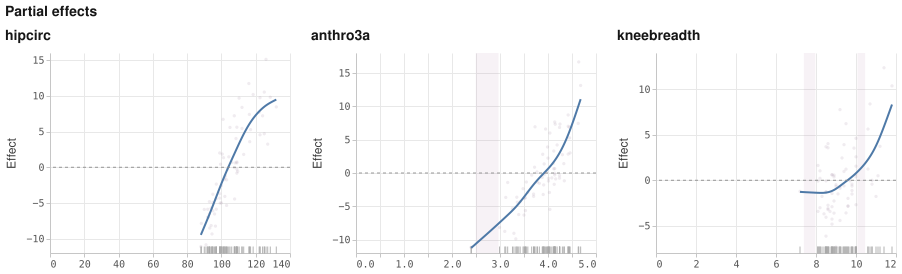

In [5]:
gam1 = mb.gamboost(
    "DEXfat ~ bbs(hipcirc, df=4) + bbs(kneebreadth, df=4) + bbs(anthro3a, df=4)",
    data=bodyfat, family=mb.Gaussian(), control=mb.boost_control(100, 0.1))
print(f"risk at mstop {float(np.asarray(gam1.risk_)[100]):.4f}"
      f"     R: 635.4451")

mb.plot.plot_partial_effects(gam1)

## Choosing the stopping iteration

```r
gam2 <- gamboost(DEXfat ~ ., baselearner = "bbs", data = bodyfat)
cvm  <- cvrisk(gam2)      ## 25-fold bootstrap by default
mstop(cvm)                ## 33
gam2[mstop(cvm)]          ## set the model to the optimal mstop
names(coef(gam2))         ## which base-learners were selected
```

`baselearner = "bbs"` applies one learner type to every predictor in a `.`
formula. mboostrs writes the terms out. Slicing is the same: `gam2[m]` in R is
`gam2[:m]` here, a Python half-open slice.

The fold draw is random and differs between the two implementations, so
neither the optimal iteration count nor the set of terms selected by it is
expected to match. Here the cross-validated optimum is 57 iterations, against
33 in R, and at 57 iterations all nine predictors have been selected, against
seven in R at 33.

In [6]:
smooth_terms = " + ".join(f"bbs({name}, df=4)" for name in predictors)
gam2 = mb.gamboost(f"DEXfat ~ {smooth_terms}", data=bodyfat,
                   family=mb.Gaussian(), control=mb.boost_control(100, 0.1))

cv = gam2.cvrisk(B=25, seed=123)
print(f"optimal mstop {cv.optimal_mstop}        R: 33")

tuned = gam2[:cv.optimal_mstop]
print(f"\nselected at the optimum ({len(set(tuned.selected))}):")
print("  " + ", ".join(sorted(set(np.asarray(tuned.selected).tolist()))))
print(f"\nR stops at 33 and selects seven of nine there: waistcirc,")
print("  hipcirc, kneebreadth, anthro3a, anthro3b, anthro3c, anthro4")

optimal mstop 57        R: 33

selected at the optimum (9):
  age, anthro3a, anthro3b, anthro3c, anthro4, elbowbreadth, hipcirc, kneebreadth, waistcirc

R stops at 33 and selects seven of nine there: waistcirc,
  hipcirc, kneebreadth, anthro3a, anthro3b, anthro3c, anthro4


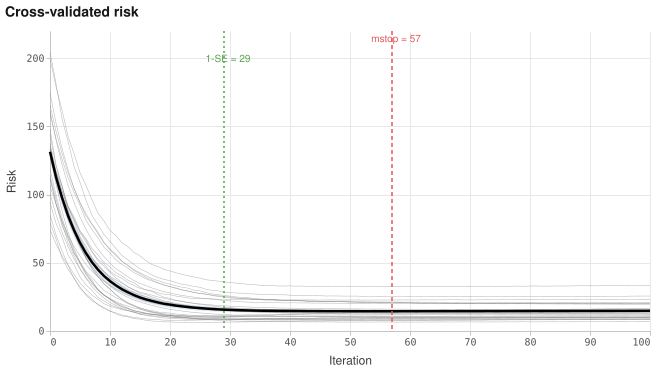

In [7]:
mb.plot.plot_cvrisk(cv).properties(title="Cross-validated risk")

Running the same fit further selects more terms, which the tutorial shows by
growing the model to 1000 iterations:

```r
gam2[1000]
names(coef(gam2))   ## now all nine
```

In [8]:
grown = gam2.continue_to(1000)
print(f"selected by iteration 1000: {len(set(grown.selected))} of "
      f"{len(predictors)} predictors")
print("  " + ", ".join(sorted(set(np.asarray(grown.selected).tolist()))))

selected by iteration 1000: 9 of 9 predictors
  age, anthro3a, anthro3b, anthro3c, anthro4, elbowbreadth, hipcirc, kneebreadth, waistcirc


## Median regression: `Quantile`

```r
glm3 <- glmboost(DEXfat ~ hipcirc + kneebreadth + anthro3a, data = bodyfat,
                 family = QuantReg(tau = 0.5),
                 control = boost_control(mstop = 500))
coef(glm3, off2int = TRUE)
```

`QuantReg(tau = 0.5)` is `Quantile(tau=0.5)` here. Median regression gives
different coefficients from the mean fit above.

The tutorial then defines the same loss by hand with `Family()` and checks it
reproduces `QuantReg`. mboostrs has no run-time equivalent: families are
compiled implementations selected by name, so a loss outside the catalogue
means writing Rust. The catalogue is in [](../methodology/families.ipynb).

In [9]:
glm3 = mb.glmboost(formula, data=bodyfat, family=mb.Quantile(tau=0.5),
                   control=mb.boost_control(500, 0.1))
median_coefficients = glm3.coef()
intercept = float(median_coefficients["(Intercept)"]) + float(glm3._offset)
rows = [{"term": "(Intercept)", "mboostrs": round(intercept, 4), "R": -63.5164}]
for name, r_value in (("hipcirc", 0.5331), ("kneebreadth", 0.7700),
                      ("anthro3a", 7.8351)):
    rows.append({"term": name,
                 "mboostrs": round(float(median_coefficients[name]), 4),
                 "R": r_value})
display(pl.DataFrame(rows))

term,mboostrs,R
"""(Intercept)""",-64.3308,-63.5164
"""hipcirc""",0.5391,0.5331
"""kneebreadth""",0.8052,0.77
"""anthro3a""",7.8149,7.8351


## The gamboostLSS tutorial

The `gamboostLSS` tutorial opens with a simulated example where the mean and
the standard deviation each depend on different predictors, so that the fitted
parameters can be compared with the truth.

```r
set.seed(1907)
n <- 150
toydata$y <- rnorm(n, mean = 1 + 2 * x1 - x2,
                      sd = exp(0.5 - 0.25 * x1 + 0.5 * x3))
lmLSS <- glmboostLSS(y ~ x1 + x2 + x3, data = toydata)
coef(lmLSS, off2int = TRUE)
```

`glmboostLSS` takes the same formula for both parameters. A dict keyed by the
family's parameter names gives them different formulas, which the tutorial does
later.

In [10]:
rng = np.random.default_rng(1907)
n = 150
toy = {name: rng.normal(size=n) for name in ("x1", "x2", "x3")}
toy["y"] = rng.normal(
    loc=1 + 2 * toy["x1"] - toy["x2"],
    scale=np.exp(0.5 - 0.25 * toy["x1"] + 0.5 * toy["x3"]))

lm_lss = mb.glmboostLSS("y ~ x1 + x2 + x3", data=toy,
                        families=mb.GaussianLSS(),
                        control=mb.boost_control(100, 0.1))

rows = []
for index, parameter in enumerate(lm_lss.param_names):
    coefficients = lm_lss.coef()[parameter]
    offset = float(lm_lss._params[index]["offset"])
    row = {"parameter": parameter,
           "intercept": round(float(np.ravel(coefficients["(Intercept)"])[0])
                              + offset, 3)}
    for name in ("x1", "x2", "x3"):
        value = coefficients.get(name)
        row[name] = round(float(np.ravel(value)[0]), 3) if value is not None else None
    rows.append(row)
display(pl.DataFrame(rows))
print("generating process:  mu = 1 + 2*x1 - x2,"
      "   log sigma = 0.5 - 0.25*x1 + 0.5*x3")

parameter,intercept,x1,x2,x3
"""mu""",0.857,2.165,-0.981,0.044
"""sigma""",0.454,-0.35,-0.111,0.528


generating process:  mu = 1 + 2*x1 - x2,   log sigma = 0.5 - 0.25*x1 + 0.5*x3


With automatic response scaling, the mu row recovers `x1` and `x2` closely
(2.165 and -0.981 against true values 2 and -1, with only 0.044 on `x3`).
The sigma row gives most of its weight to `x1` (-0.350, true -0.25) and `x3`
(0.528, true 0.5), the two that generated it, and a smaller coefficient
(-0.111) to `x2`, which did not. Each parameter has its own selection
path over the same three candidates.

```r
muFit    <- fitted(lmLSS, parameter = "mu")
sigmaFit <- fitted(lmLSS, parameter = "sigma", type = "response")
```

The tutorial then compares the fitted parameters with the values used to
generate the data.

In [11]:
mu_fitted = np.asarray(lm_lss.predict(parameter="mu", type="response"))
sigma_fitted = np.asarray(lm_lss.predict(parameter="sigma", type="response"))
mu_truth = 1 + 2 * toy["x1"] - toy["x2"]
sigma_truth = np.exp(0.5 - 0.25 * toy["x1"] + 0.5 * toy["x3"])

display(pl.DataFrame({
    "observation": np.arange(1, 6),
    "mu fitted": np.round(mu_fitted[:5], 3),
    "mu truth": np.round(mu_truth[:5], 3),
    "sigma fitted": np.round(sigma_fitted[:5], 3),
    "sigma truth": np.round(sigma_truth[:5], 3),
}))
print(f"correlation with the truth:  mu {np.corrcoef(mu_fitted, mu_truth)[0, 1]:.3f}"
      f"   sigma {np.corrcoef(sigma_fitted, sigma_truth)[0, 1]:.3f}")

observation,mu fitted,mu truth,sigma fitted,sigma truth
1,3.771,3.698,1.855,2.005
2,3.19,3.13,2.396,2.558
3,0.005,0.403,2.524,1.91
4,0.179,0.373,1.525,1.582
5,-3.659,-3.143,2.157,1.883


correlation with the truth:  mu 0.999   sigma 0.979


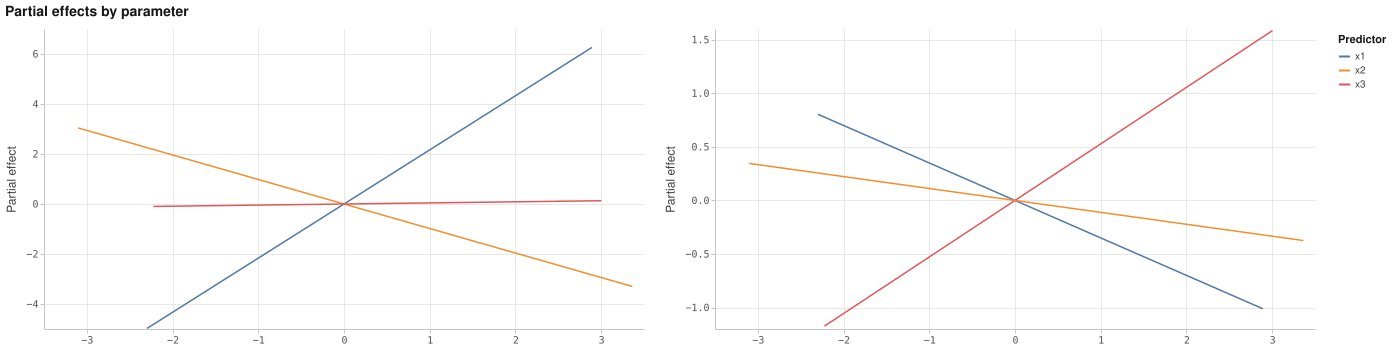

In [12]:
mb.plot.plot_lss(lm_lss).properties(title="Partial effects by parameter")

## India child malnutrition data

```r
data("india")
names(india)
```

The tutorial's applied example is childhood undernutrition in India, with
stunting as the response. mboostrs includes the same data.

The tutorial's model also contains a spatial effect of the district, fitted
with `bmrf`, a Markov random field learner whose penalty pulls the effects of
neighbouring districts toward each other, and draws that effect as a district
map with the map functions of the R package `BayesX`. mboostrs does not ship
the district neighbourhood structure of the India data or a map-drawing
function, so the fit here contains only the three smooth terms.
[](../cases/munich_rents.ipynb) fits a `bmrf` district effect on the Munich
rent survey, whose neighbourhood structure is included.

In [13]:
india = mb.datasets.india()
print(f"{india.height} children, {india.width} columns")
print(", ".join(india.columns))

lss = mb.gamboostLSS(
    "stunting ~ bbs(cage, df=4) + bbs(mbmi, df=4) + bbs(mage, df=4)",
    data=india, families=mb.GaussianLSS(),
    control=mb.boost_control(200, 0.1))
parameters = lss.params(type="response")
print(f"\nfitted mu    {np.asarray(parameters['mu']).min():.2f} to "
      f"{np.asarray(parameters['mu']).max():.2f}")
print(f"fitted sigma {np.asarray(parameters['sigma']).min():.2f} to "
      f"{np.asarray(parameters['sigma']).max():.2f}")

4000 children, 7 columns
stunting, cbmi, cage, mbmi, mage, mcdist, mcdist_lab



fitted mu    -3.05 to 0.78
fitted sigma 1.07 to 1.84


## Differences between the tutorials and mboostrs

The differences between the tutorial calls and mboostrs:

| tutorial writes | mboostrs writes |
|---|---|
| `coef(fit, off2int = TRUE)` | intercept and offset reported separately; add them |
| `coef(fit, which = "")` | unselected terms are absent rather than reported as zero |
| `gamboost(y ~ ., baselearner = "bbs")` | the terms written out, `bbs(x, df=4)` each |
| `bbs(x)` with `dfbase` | `df` per learner |
| `fit[m]` | `fit[:m]`, a Python slice |
| `plot(fit)` | `mboostrs.plot.plot_coef_path`, `plot_partial_effects`, `plot_cvrisk` |
| `QuantReg(tau = 0.5)` | `Quantile(tau=0.5)` |
| `Family(...)` for a new loss | no equivalent; families are compiled |
| `fitted(fit, parameter = "mu")` | `fit.predict(parameter="mu", type="response")` |

[](r_migration.ipynb) covers the mapping in full, including the parts these
tutorials do not reach.